In [ ]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
load_dotenv()
print("Environment variables loaded successfully.")


In [2]:
llm_model_google = ChatGoogleGenerativeAI(model="gemini-3.8-flash")
llm_model_openrouter = ChatOpenAI(
     api_key=os.environ.get("OPENROUTER_API_KEY"),
        base_url="https://openrouter.ai/api/v1",
        model="nvidia/nemotron-3.5-lightning:free"
)

In [3]:
llm_model_openrouter.invoke("Capital of France?")

AIMessage(content='Paris is the capital of France.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 139, 'prompt_tokens': 20, 'total_tokens': 159, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 129, 'rejected_prediction_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0, 'cache_write_tokens': 0, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'nvidia/nemotron-3.5-lightning:free', 'system_fingerprint': None, 'id': 'gen-1791087151-eOWq5uyHGSFSx9kr12pM', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1051d-0616-70d2-be84-5e930b99c8af-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 20, 'output_tokens': 139, 'total_tokens': 159, 'input_

In [4]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str

In [5]:
def generate_outline(state: BlogState) -> BlogState:
    prompt = f"Generate a detailed outline for a blog post titled '{state['title']}'."
    response = llm_model_openrouter.invoke(prompt)
    state['outline'] = response.content
    return state

In [6]:
def generate_content(state: BlogState) -> BlogState:
    prompt = f"Write a blog post based on the following outline:\n{state['outline']}"
    response = llm_model_openrouter.invoke(prompt)
    state['content'] = response.content
    return state

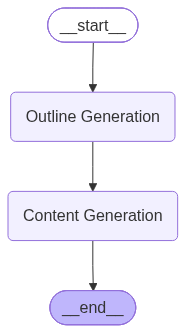

In [7]:
graph = StateGraph(BlogState)
graph.add_node('Outline Generation', generate_outline)
graph.add_node('Content Generation', generate_content)

graph.add_edge(START, 'Outline Generation')
graph.add_edge('Outline Generation', 'Content Generation')
graph.add_edge('Content Generation', END)

workflow = graph.compile()
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [8]:
initial_state = {'title': 'The Future of AI'}
workflow.invoke(initial_state)

{'title': 'The Future of AI',
 'outline': '# Blog Post Outline: "The Future of AI"\n\n**Target Length:** 1,800–2,500 words  \n**Tone:** Forward-looking, balanced, research-informed, practical  \n**SEO Focus:** Broad keyword coverage ("future of AI," "AI trends 2025," "AI impact on jobs," "ethical AI development")  \n\n---\n\n## 1. Title & Meta\n- **Title:** The Future of AI: Trends, Transformations, and How to Prepare\n- **Meta Description:** A deep dive into where artificial intelligence is headed technologically, economically, and ethically—and what individuals, businesses, and policymakers can do today to shape a beneficial future.\n- **Focus Keyword:** future of AI\n- **Secondary Keywords:** AI trends 2025, artificial intelligence impacts, ethical AI, AGI vs. narrow AI, AI workforce transformation\n\n---\n\n## 2. Introduction (~150–200 words)\n- **Hook:** A provocative quote or statistic (e.g., “By 2030, AI could contribute $15.7T to the global economy–or displace half of current e